# Tata Steel – Stock Market and Financial Statement Analysis

This notebook analyses Tata Steel historical stock data and financial statements.

**Input files expected in the same folder as this notebook:**
- `TATASTEEL_Historical_Data.csv`
- `TATASTEEL_Financial_Data.xlsx`

Run the cells from top to bottom. If your files have different names, update the file paths in the data-loading cell.


## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
sns.set_theme(style="whitegrid")


## 2. Load the datasets

In [4]:
stock_file = "TATASTEEL_Historical_Data.csv"
financial_file = "TATASTEEL_Financial_Data.xlsx"

stock_raw = pd.read_csv(stock_file)
financial_sheets = pd.read_excel(financial_file, sheet_name=None)

print("Stock data shape:", stock_raw.shape)
print("Available financial sheets:", list(financial_sheets.keys()))

display(stock_raw.head())


Stock data shape: (1937, 6)
Available financial sheets: ['Income Statement', 'Balance Sheet', 'Cash Flow']


,Price,Close,High,Low,Open,Volume
0,Ticker,TATASTEEL.NS,TATASTEEL.NS,TATASTEEL.NS,TATASTEEL.NS,TATASTEEL.NS
1,Date,NaN,NaN,NaN,NaN,NaN
2,2019-01-01,41.323265075683594,42.0243383942749,41.146994234663616,41.98427767307139,41281730
3,2019-01-02,39.55256271362305,40.606174865608914,39.42035955678517,40.54207525389199,117473500
4,2019-01-03,38.55904006958008,39.512498869164844,38.478918611491096,39.50048095609527,135329440


## 3. Clean and prepare historical stock data

In [5]:
# Standardise column names and remove blank rows
stock = stock_raw.copy()
stock.columns = [str(c).strip() for c in stock.columns]
stock = stock.dropna(how="all")

# Convert expected numeric fields when present
for col in ["Open", "High", "Low", "Close", "Volume"]:
    if col in stock.columns:
        stock[col] = pd.to_numeric(
            stock[col].astype(str).str.replace(",", "", regex=False),
            errors="coerce"
        )

if "Date" in stock.columns:
    stock["Date"] = pd.to_datetime(stock["Date"], errors="coerce")

# Exclude rows that are metadata or do not contain a valid date
if "Date" in stock.columns:
    stock = stock.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

# Remove exact duplicate rows
stock = stock.drop_duplicates().reset_index(drop=True)

print("Cleaned stock data shape:", stock.shape)
display(stock.head())
display(stock.tail())
stock.info()


Cleaned stock data shape: (1937, 6)


,Price,Close,High,Low,Open,Volume
0,Ticker,NaN,NaN,NaN,NaN,NaN
1,Date,NaN,NaN,NaN,NaN,NaN
2,2019-01-01,41.323265,42.024338,41.146994,41.984278,41281730.0
3,2019-01-02,39.552563,40.606175,39.420360,40.542075,117473500.0
4,2019-01-03,38.559040,39.512499,38.478919,39.500481,135329440.0


,Price,Close,High,Low,Open,Volume
1932,2026-10-26,169.940002,169.940002,165.509995,167.669998,22624704.0
1933,2026-10-27,171.419998,172.449997,168.199997,169.190002,27060892.0
1934,2026-10-28,169.270004,170.990005,168.089996,170.649994,12894674.0
1935,2026-10-29,169.460007,169.649994,167.910004,168.710007,13728789.0
1936,2026-10-30,167.600006,168.690002,167.210007,168.500000,15606595.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1937 entries, 0 to 1936
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   1937 non-null   object 
 1   Close   1935 non-null   float64
 2   High    1935 non-null   float64
 3   Low     1935 non-null   float64
 4   Open    1935 non-null   float64
 5   Volume  1935 non-null   float64
dtypes: float64(5), object(1)
memory usage: 90.9+ KB


## 4. Explore stock data and descriptive statistics

In [6]:
display(stock.describe(include="all"))

if "Date" in stock.columns and not stock.empty:
    print("Start date:", stock["Date"].min())
    print("End date:", stock["Date"].max())

print("Missing values by column:")
display(stock.isna().sum())

print("Duplicate rows:", stock.duplicated().sum())


,Price,Close,High,Low,Open,Volume
count,1937,1935.000000,1935.000000,1935.000000,1935.000000,1.935000e+03
unique,1937,NaN,NaN,NaN,NaN,NaN
top,2026-10-30,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,105.528596,106.931181,104.195180,105.672349,8.222003e+07
std,NaN,52.424863,52.929995,51.926402,52.504807,7.485795e+07
min,NaN,20.862608,22.030090,20.624178,21.561453,0.000000e+00
25%,NaN,52.464611,53.270141,51.538889,52.593246,3.039610e+07
50%,NaN,106.749229,108.385237,105.305925,106.759957,5.590778e+07
75%,NaN,147.396988,149.058190,145.793236,147.449642,1.110584e+08


Missing values by column:


,0
Price,0
Close,2
High,2
Low,2
Open,2
Volume,2


Duplicate rows: 0


## 5. Calculate daily returns and moving averages

In [8]:
if "Close" in stock.columns:
    stock["Daily_Return"] = stock["Close"].pct_change() * 100
    stock["MA_20"] = stock["Close"].rolling(window=20).mean()
    stock["MA_50"] = stock["Close"].rolling(window=50).mean()

    display(stock[["Close", "Daily_Return", "MA_20", "MA_50"]].tail())

    daily_volatility = stock["Daily_Return"].std()
    annualized_volatility = daily_volatility * np.sqrt(252)
    print(f"Daily return standard deviation: {daily_volatility:.2f}%")
    print(f"Annualized historical volatility (approx.): {annualized_volatility:.2f}%")


,Close,Daily_Return,MA_20,MA_50
1932,169.940002,1.353852,176.643001,181.9600
1933,171.419998,0.870893,175.815501,181.6914
1934,169.270004,-1.254226,174.964001,181.4068
1935,169.460007,0.112248,174.037001,181.0760
1936,167.600006,-1.097604,173.202001,180.7180


Daily return standard deviation: 2.24%
Annualized historical volatility (approx.): 35.57%


## 6. Analyse financial statement sheets

In [9]:
# Display a preview of each worksheet.
for sheet_name, frame in financial_sheets.items():
    print("\\n---", sheet_name, "---")
    print("Shape:", frame.shape)
    display(frame.head())


\n--- Income Statement ---
Shape: (53, 6)


,Unnamed: 0,2026-03-31 00:00:00,2025-03-31 00:00:00,2024-03-31 00:00:00,2023-03-31 00:00:00,2022-03-31 00:00:00
0,Tax Effect Of Unusual Items,-2.171649e+09,-9.486600e+08,-1.991643e+10,1.878870e+09,NaN
1,Tax Rate For Calcs,3.183020e-01,3.000000e-01,3.000000e-01,3.000000e-01,NaN
2,Normalized EBITDA,3.577502e+11,2.649643e+11,2.288770e+11,3.324894e+11,NaN
3,Total Unusual Items,-6.822600e+09,-3.162200e+09,-6.638810e+10,6.262900e+09,NaN
4,Total Unusual Items Excluding Goodwill,-6.822600e+09,-3.162200e+09,-6.638810e+10,6.262900e+09,NaN


\n--- Balance Sheet ---
Shape: (89, 6)


,Unnamed: 0,2026-03-31 00:00:00,2025-03-31 00:00:00,2024-03-31 00:00:00,2023-03-31 00:00:00,2022-03-31 00:00:00
0,Treasury Shares Number,1.168393e+07,1.168393e+07,1.168393e+07,11683930,NaN
1,Ordinary Shares Number,1.247185e+10,1.247185e+10,1.247185e+10,12209853070,NaN
2,Share Issued,1.248353e+10,1.248353e+10,1.248353e+10,12221537000,NaN
3,Net Debt,7.607144e+11,7.935885e+11,7.449308e+11,658878000000,NaN
4,Total Debt,9.238168e+11,9.480105e+11,8.708212e+11,848930500000,NaN


\n--- Cash Flow ---
Shape: (50, 6)


,Unnamed: 0,2026-03-31 00:00:00,2025-03-31 00:00:00,2024-03-31 00:00:00,2023-03-31 00:00:00,2022-03-31 00:00:00
0,Free Cash Flow,2.050541e+11,7.467060e+10,2.094070e+10,7.540590e+10,NaN
1,Repayment Of Debt,-2.389678e+11,-1.607862e+11,-1.175089e+11,-4.605680e+10,NaN
2,Issuance Of Debt,1.209234e+11,2.389304e+11,1.332949e+11,1.676865e+11,NaN
3,Issuance Of Capital Stock,NaN,NaN,0.000000e+00,1.370000e+07,3.257400e+09
4,Capital Expenditure,-1.455905e+11,-1.567052e+11,-1.820660e+11,-1.414249e+11,NaN


### Prepare financial statement data

The workbook may use different layouts for each statement. Inspect the previews above and adjust the column names below if required. The following cell performs basic cleaning without assuming a particular financial-year layout.


In [10]:
financial_clean = {}

for sheet_name, frame in financial_sheets.items():
    temp = frame.copy()
    temp.columns = [str(c).strip() for c in temp.columns]
    temp = temp.dropna(how="all")
    financial_clean[sheet_name] = temp

# Example descriptive summary for numeric columns in each sheet
for sheet_name, frame in financial_clean.items():
    numeric = frame.select_dtypes(include=np.number)
    print("\\nNumeric summary:", sheet_name)
    if not numeric.empty:
        display(numeric.describe())
    else:
        print("No numeric columns detected automatically.")


\nNumeric summary: Income Statement


,2026-03-31 00:00:00,2025-03-31 00:00:00,2024-03-31 00:00:00,2023-03-31 00:00:00,2022-03-31 00:00:00
count,5.100000e+01,5.100000e+01,5.200000e+01,5.300000e+01,2.000000e+00
mean,2.818509e+11,2.506180e+11,2.358963e+11,2.773224e+11,1.263400e+09
std,5.736716e+11,5.510937e+11,5.860017e+11,6.008907e+11,1.786717e+09
min,-6.440010e+10,-6.546400e+10,-7.036750e+10,-5.953060e+10,0.000000e+00
25%,2.707700e+09,1.914400e+09,-1.358191e+10,1.878870e+09,6.317000e+08
50%,1.079387e+11,3.420510e+10,1.226982e+10,8.075350e+10,1.263400e+09
75%,1.533529e+11,1.398680e+11,1.040435e+11,1.334443e+11,1.895100e+09
max,2.302935e+12,2.168404e+12,2.272962e+12,2.416362e+12,2.526800e+09


\nNumeric summary: Balance Sheet


,2026-03-31 00:00:00,2025-03-31 00:00:00,2024-03-31 00:00:00,2023-03-31 00:00:00,2022-03-31 00:00:00
count,8.600000e+01,8.600000e+01,8.800000e+01,8.900000e+01,3.000000e+00
mean,4.156490e+11,3.870067e+11,3.654116e+11,3.793960e+11,9.924167e+09
std,7.441605e+11,6.779397e+11,6.418040e+11,6.395673e+11,1.525897e+10
min,-1.388377e+12,-1.184240e+12,-1.070506e+12,-9.576546e+11,1.560000e+08
25%,1.247668e+10,1.247249e+10,1.177764e+10,1.221240e+10,1.132450e+09
50%,7.023035e+10,5.821870e+10,5.718545e+10,6.990830e+10,2.108900e+09
75%,5.988187e+11,6.244114e+11,4.976232e+11,5.198040e+11,1.480825e+10
max,3.389715e+12,3.043768e+12,2.840422e+12,2.880217e+12,2.750760e+10


\nNumeric summary: Cash Flow


,2026-03-31 00:00:00,2025-03-31 00:00:00,2024-03-31 00:00:00,2023-03-31 00:00:00,2022-03-31 00:00:00
count,4.600000e+01,4.600000e+01,4.900000e+01,4.900000e+01,4.000000e+00
mean,-2.646076e+09,6.975217e+09,-3.060976e+09,4.519831e+09,-2.386245e+10
std,1.110900e+11,9.307816e+10,8.069924e+10,8.840181e+10,5.423970e+10
min,-2.389678e+11,-1.607862e+11,-1.820660e+11,-1.867984e+11,-1.052220e+11
25%,-4.489870e+10,-2.628368e+10,-4.428800e+10,-4.605680e+10,-2.386245e+10
50%,-2.530000e+08,2.510000e+08,1.920000e+07,1.370000e+07,3.257400e+09
75%,4.414308e+10,5.353660e+10,2.599370e+10,5.214180e+10,3.257400e+09
max,3.506446e+11,2.389304e+11,2.030067e+11,2.168308e+11,3.257400e+09


## 7. Visualise historical closing price

In [11]:
if {"Date", "Close"}.issubset(stock.columns):
    plt.figure(figsize=(12, 5))
    plt.plot(stock["Date"], stock["Close"], label="Closing Price")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.title("Tata Steel Historical Closing Price")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 8. Visualise trading volume

In [12]:
if {"Date", "Volume"}.issubset(stock.columns):
    plt.figure(figsize=(12, 5))
    plt.plot(stock["Date"], stock["Volume"])
    plt.xlabel("Date")
    plt.ylabel("Volume")
    plt.title("Tata Steel Trading Volume")
    plt.tight_layout()
    plt.show()


## 9. Closing price with moving averages

In [13]:
if {"Date", "Close", "MA_20", "MA_50"}.issubset(stock.columns):
    plt.figure(figsize=(12, 5))
    plt.plot(stock["Date"], stock["Close"], label="Close", alpha=0.65)
    plt.plot(stock["Date"], stock["MA_20"], label="20-day moving average")
    plt.plot(stock["Date"], stock["MA_50"], label="50-day moving average")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.title("Closing Price and Moving Averages")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 10. Distribution of daily returns

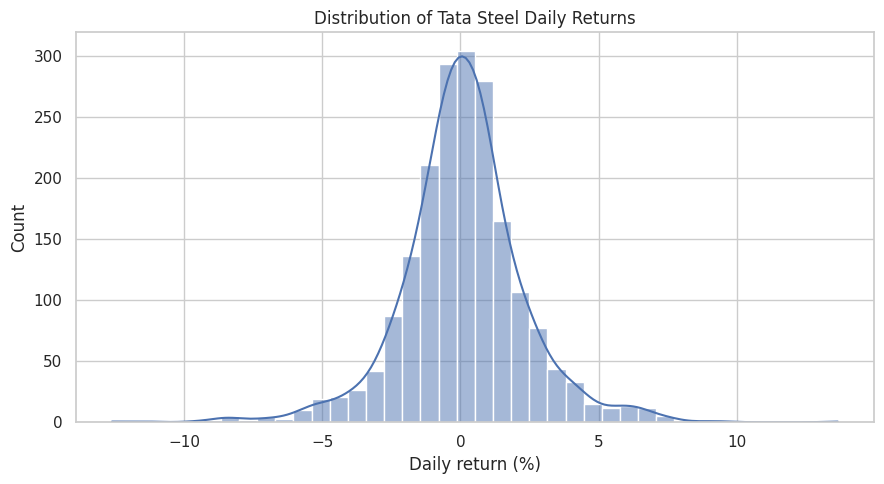

In [14]:
if "Daily_Return" in stock.columns:
    returns = stock["Daily_Return"].dropna()
    plt.figure(figsize=(9, 5))
    sns.histplot(returns, bins=40, kde=True)
    plt.xlabel("Daily return (%)")
    plt.title("Distribution of Tata Steel Daily Returns")
    plt.tight_layout()
    plt.show()


## 11. Correlation analysis

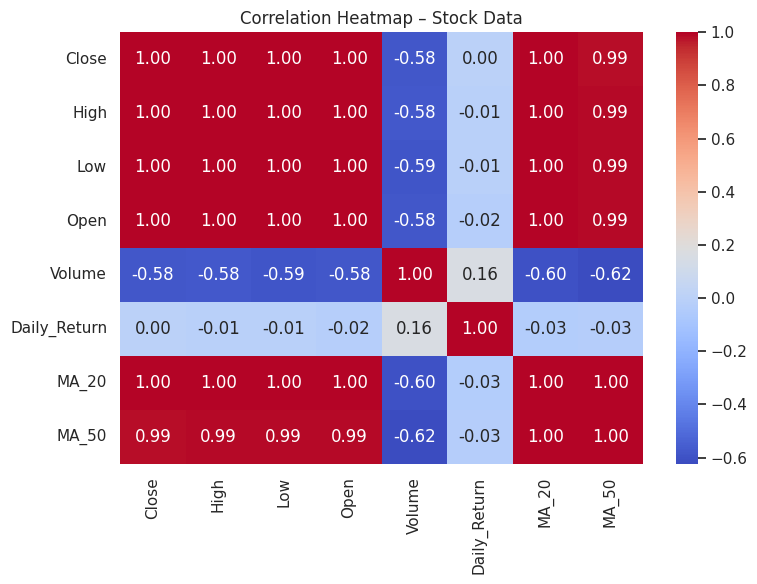

,Close,High,Low,Open,Volume,Daily_Return,MA_20,MA_50
Close,1.000000,0.999732,0.999721,0.999302,-0.581714,0.004078,0.995150,0.987289
High,0.999732,1.000000,0.999623,0.999699,-0.578582,-0.009344,0.995510,0.987520
Low,0.999721,0.999623,1.000000,0.999612,-0.588207,-0.008293,0.995314,0.987581
Open,0.999302,0.999699,0.999612,1.000000,-0.584933,-0.024183,0.995727,0.987904
Volume,-0.581714,-0.578582,-0.588207,-0.584933,1.000000,0.157027,-0.601910,-0.623084
Daily_Return,0.004078,-0.009344,-0.008293,-0.024183,0.157027,1.000000,-0.033862,-0.032780
MA_20,0.995150,0.995510,0.995314,0.995727,-0.601910,-0.033862,1.000000,0.995303
MA_50,0.987289,0.987520,0.987581,0.987904,-0.623084,-0.032780,0.995303,1.000000


In [15]:
numeric_stock = stock.select_dtypes(include=np.number)
if numeric_stock.shape[1] >= 2:
    corr = numeric_stock.corr()
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap – Stock Data")
    plt.tight_layout()
    plt.show()
    display(corr)


## 12. Box plot of closing prices

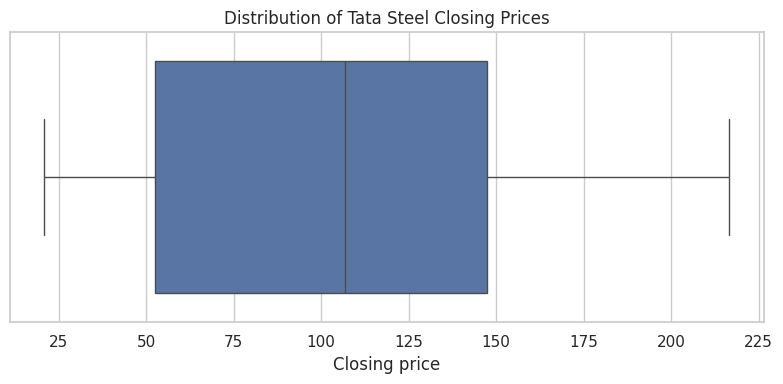

In [16]:
if "Close" in stock.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=stock["Close"])
    plt.xlabel("Closing price")
    plt.title("Distribution of Tata Steel Closing Prices")
    plt.tight_layout()
    plt.show()


## 13. Key observations

Use the outputs and charts above to write the observations for your submission:
- Overall movement in Tata Steel's closing price.
- Periods of higher and lower trading volume.
- How the moving averages compare with the closing price.
- Shape and spread of daily returns.
- Relationships between numeric stock variables.
- Important changes visible in the income statement, balance sheet and cash flow statement.

**Note:** Financial statement units and year labels should be taken from the source workbook. Do not assume units if they are not specified.
